# Hotel bookings dashboard: data, charts and export

**Data sources:** `data/processed/hotel_bookings_clean.csv` (cleaned in Part 1 from Antonio, N., de Almeida, A. and Nunes, L. (2019), *Hotel booking demand datasets*, Data in Brief, 22, 41–49, https://doi.org/10.1016/j.dib.2018.11.126) `data/processed/country_names.csv` (Part 3, ISO 3166 names from pycountry) and `data/external/world-110m.json` (world map at 1:110 million, TopoJSON World Atlas from Natural Earth, public domain, copied from the npm package vega-datasets 3.2.1).
**Date:** 2026-11-05
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** This notebook builds the two-screen dashboard of Part 6 for the persona Natalia, a tourism analyst: it prepares small aggregated tables with pandas, builds every chart with Vega-Altair, and writes `data.js` and `specs.js` straight into `../dashboard/`. It answers the seven questions of Part 2 (main screen: Q1, Q5, Q7; detail screen: Q2, Q3, Q4, Q6).

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation: aggregated tables](#3.-Cleaning-and-preparation:-aggregated-tables)
4. [Analysis: checks of the tables](#4.-Analysis:-checks-of-the-tables)
5. [Accessible visualisation: the charts](#5.-Accessible-visualisation:-the-charts)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import calendar
import json
import re
import sys
import warnings
from decimal import Decimal, ROUND_HALF_UP
from pathlib import Path

import pandas as pd
import altair as alt
import pycountry
import vl_convert as vlc     # renders the Vega-Lite specs to SVG, to check what the charts draw
from IPython.display import SVG

# Global Altair configuration (jupyter-accessible-notebook and wcag-accessibility skills)
alt.data_transformers.disable_max_rows()   # kept as the skill asks; only aggregated tables are charted
alt.renderers.enable('svg')                # SVG, never canvas

# Paths
CLEAN_FILE    = Path('../../data/processed/hotel_bookings_clean.csv')
NAMES_FILE    = Path('../../data/processed/country_names.csv')
WORLD_FILE    = Path('../../data/external/world-110m.json')    # world map (TopoJSON), vega-datasets 3.2.1
PROCESSED_DIR = Path('../../data/processed')
DASHBOARD_DIR = Path('../dashboard')
OUTPUT_DIR    = Path('build_dashboard_output')
for folder in [PROCESSED_DIR, DASHBOARD_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

SEED = 112358   # fixed seed of the project; this notebook has no randomness, so it is not used

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| altair', alt.__version__,
      '| Vega-Lite', alt.SCHEMA_VERSION, '| vl-convert', vlc.__version__,
      '| pycountry', pycountry.__version__ if hasattr(pycountry, '__version__') else '26.2.16')

Python 3.13.18 | pandas 3.0.5 | altair 6.2.2 | Vega-Lite v6.4.1 | vl-convert 1.9.0 | pycountry 26.2.16


## 1. Data loading

In [2]:
# ── Load the cleaned bookings and add the country names ──────────────────────
bookings = pd.read_csv(CLEAN_FILE, keep_default_na=False)
names = pd.read_csv(NAMES_FILE, keep_default_na=False)
bookings = bookings.merge(names[['country', 'country_name']], on='country', how='left', validate='many_to_one')

# Date fields used by the dashboard
bookings['arrival_date'] = pd.to_datetime(bookings['arrival_date'])
bookings['arrival_month'] = bookings['arrival_date'].dt.to_period('M').dt.to_timestamp()
bookings['year'] = bookings['arrival_date'].dt.year
bookings['calendar_month'] = bookings['arrival_date'].dt.month

print(f'Rows: {len(bookings):,} | columns: {bookings.shape[1]} | bookings without a country name: {bookings["country_name"].isna().sum()}')
bookings[['hotel', 'arrival_month', 'country_name', 'is_canceled', 'total_guests', 'total_nights', 'lead_time', 'adr']].head()

Rows: 119,201 | columns: 39 | bookings without a country name: 0


,hotel,arrival_month,country_name,is_canceled,total_guests,total_nights,lead_time,adr
0,Resort Hotel,2015-07-01,Portugal,0,2,0,342,0.0
1,Resort Hotel,2015-07-01,Portugal,0,2,0,737,0.0
2,Resort Hotel,2015-07-01,United Kingdom,0,1,1,7,75.0
3,Resort Hotel,2015-07-01,United Kingdom,0,1,1,13,75.0
4,Resort Hotel,2015-07-01,United Kingdom,0,2,2,14,98.0


### Decision: what is a "stay", a "guest" and a "visitor"

**Context:** the dashboard counts bookings, but Natalia's questions are about people who came.

**Decision taken:** a **stay** is a booking that was not cancelled (`is_canceled` = 0); **guests** (visitors) are the people of those stays (`total_guests`); the **cancellation rate** uses all bookings. Prices are the median `adr` of stays with a price above 0, as in Part 1. The **top 10 countries** are the ten with the most guests over both hotels and the whole period (students' decision before task 6.1); every other country, and the bookings without a country ("Unknown"), form "Other".

> ⚠️ **Limitation:** duplicated rows are kept (cleaning rule 1), so some counts and Portugal's cancellation rate are inflated; the dashboard shows a note.

## 2. Initial exploration

In [3]:
# ── The numbers every table must add up to ───────────────────────────────────
stays = bookings[bookings['is_canceled'] == 0]
paid_stays = stays[stays['adr'] > 0]

totals = pd.Series({
    'bookings': len(bookings),
    'cancelled bookings': int(bookings['is_canceled'].sum()),
    'stays': len(stays),
    'guests of stays': int(stays['total_guests'].sum()),
    'paid stays (price above 0)': len(paid_stays),
}, name='total')
totals

bookings                      119201
cancelled bookings             44194
stays                          75007
guests of stays               145980
paid stays (price above 0)     73385
Name: total, dtype: int64

In [4]:
# ── Top 10 countries by guests (both hotels, whole period) ───────────────────
guests_by_country = stays.groupby('country_name')['total_guests'].sum().sort_values(ascending=False)
TOP_10 = guests_by_country.drop('Unknown', errors='ignore').head(10).index.tolist()
top_10_table = guests_by_country.loc[TOP_10].rename('guests').to_frame()
top_10_table['% of all guests'] = (100 * top_10_table['guests'] / totals['guests of stays']).round(1)
print(f"Top 10 together: {top_10_table['% of all guests'].sum():.1f} % of all guests")
top_10_table

Top 10 together: 82.0 % of all guests


,guests,% of all guests
country_name,,
Portugal,37655,25.8
United Kingdom,19246,13.2
France,17299,11.9
Spain,13213,9.1
Germany,11659,8.0
Ireland,5102,3.5
Italy,4894,3.4
Belgium,3855,2.6
Netherlands,3374,2.3


**Finding:** the ten countries hold 82.0 % of all guests, so "Other" is a single, modest group. Portugal is still first, but with 25.8 % of guests instead of the 40.7 % of bookings seen in Part 1: many Portuguese bookings were cancelled, so counting visitors instead of bookings changes the picture.

## 3. Cleaning and preparation: aggregated tables

No raw row is charted (architecture.md). Five small tables are made with pandas, at the level the Part 5 interactions need:

| Table | Level | Used by |
|---|---|---|
| `month_hotel` | arrival month × hotel | C1, C2, C3 (filters I1, I2; month highlight I5) |
| `country_month` | country group × hotel × year × calendar month | C4, C6 (filters, country selection I7, sort I9) |
| `country_map` | country (ISO) × hotel × year | C5 map |
| `filter_kpis` | each hotel filter × year filter (12 combinations) | KPIs of both screens |
| `country_medians` | country group × hotel filter × year filter | C7, C8 and the selected-country KPIs |

Sums and counts can be added up by the charts after filtering; **medians cannot**, so they are computed here for every filter combination.

In [5]:
# ── Filter combinations of the dashboard (I1 hotel x I2 year) ────────────────
HOTEL_FILTERS = ['Both', 'City Hotel', 'Resort Hotel']
YEAR_FILTERS = ['All', 2015, 2016, 2017]

def filtered(table, hotel_filter, year_filter):
    """Rows of a table that a given hotel filter and year filter keep."""
    keep = pd.Series(True, index=table.index)
    if hotel_filter != 'Both':
        keep &= table['hotel'] == hotel_filter
    if year_filter != 'All':
        keep &= table['year'] == year_filter
    return table[keep]

# Country group: one of the top 10, or Other (all other countries and 'Unknown')
for table in [bookings]:
    table['country_group'] = table['country_name'].where(table['country_name'].isin(TOP_10), 'Other')
stays = bookings[bookings['is_canceled'] == 0]
paid_stays = stays[stays['adr'] > 0]
print('Filter combinations:', len(HOTEL_FILTERS) * len(YEAR_FILTERS), '| country groups:', bookings['country_group'].nunique())

Filter combinations: 12 | country groups: 11


In [6]:
# ── Table 1: month x hotel (C1 guests, C2 cancellation rate, C3 median price) ─
month_hotel = (bookings.groupby(['arrival_month', 'hotel'])
               .agg(bookings=('is_canceled', 'size'), cancelled=('is_canceled', 'sum'))
               .join(stays.groupby(['arrival_month', 'hotel']).agg(stays=('is_canceled', 'size'), guests=('total_guests', 'sum')))
               .join(paid_stays.groupby(['arrival_month', 'hotel']).agg(median_price=('adr', 'median')))
               .reset_index())
month_hotel['year'] = month_hotel['arrival_month'].dt.year
month_hotel['cancel_rate'] = (100 * month_hotel['cancelled'] / month_hotel['bookings']).round(1)
month_hotel['median_price'] = month_hotel['median_price'].round(1)
print(f'month_hotel: {len(month_hotel)} rows')
month_hotel.head()

month_hotel: 52 rows


,arrival_month,hotel,bookings,cancelled,stays,guests,median_price,year,cancel_rate
0,2015-07-01,City Hotel,1396,939,457,852,80.0,2015,67.3
1,2015-07-01,Resort Hotel,1377,320,1057,2318,123.0,2015,23.2
2,2015-08-01,City Hotel,2470,1228,1242,2451,81.0,2015,49.7
3,2015-08-01,Resort Hotel,1409,366,1043,2344,153.4,2015,26.0
4,2015-09-01,City Hotel,3524,1542,1982,3456,100.6,2015,43.8


In [7]:
# ── Table 2: country group x hotel x year x calendar month (C4 and C6) ───────
country_month = (bookings.groupby(['country_group', 'hotel', 'year', 'calendar_month'])
                 .agg(bookings=('is_canceled', 'size'), cancelled=('is_canceled', 'sum'))
                 .join(stays.groupby(['country_group', 'hotel', 'year', 'calendar_month'])
                       .agg(guests=('total_guests', 'sum')))
                 .fillna({'guests': 0}).reset_index())
country_month['guests'] = country_month['guests'].astype(int)
print(f'country_month: {len(country_month)} rows')
country_month.head()

country_month: 569 rows


,country_group,hotel,year,calendar_month,bookings,cancelled,guests
0,Belgium,City Hotel,2015,8,18,0,35
1,Belgium,City Hotel,2015,9,37,0,72
2,Belgium,City Hotel,2015,10,27,0,46
3,Belgium,City Hotel,2015,11,18,0,38
4,Belgium,City Hotel,2015,12,24,2,44


In [8]:
# ── Table 3: country x hotel x year for the map (C5), with the ISO numeric code ─

def iso_numeric(alpha_3):
    """ISO 3166 numeric code of a three-letter code (current or former), as used by world maps."""
    country = pycountry.countries.get(alpha_3=alpha_3)
    if country is None:
        country = next((old for old in pycountry.historic_countries if getattr(old, 'alpha_3', None) == alpha_3), None)
    return int(country.numeric) if country is not None and getattr(country, 'numeric', None) else None

country_map = (stays[stays['country'] != 'Unknown']
               .groupby(['country', 'country_name', 'hotel', 'year'])
               .agg(guests=('total_guests', 'sum')).reset_index())
country_map['iso_numeric'] = country_map['country'].map(iso_numeric)
print(f'country_map: {len(country_map)} rows | codes without a numeric code: '
      f'{sorted(country_map.loc[country_map["iso_numeric"].isna(), "country"].unique())}')
country_map.head()

country_map: 586 rows | codes without a numeric code: []


,country,country_name,hotel,year,guests,iso_numeric
0,ABW,Aruba,City Hotel,2016,3,533
1,ABW,Aruba,City Hotel,2017,2,533
2,AGO,Angola,City Hotel,2015,72,24
3,AGO,Angola,City Hotel,2016,88,24
4,AGO,Angola,City Hotel,2017,87,24


In [9]:
# ── Table 4: KPIs for each filter combination ─────────────────────────────────
kpi_rows = []
for hotel_filter in HOTEL_FILTERS:
    for year_filter in YEAR_FILTERS:
        all_rows = filtered(bookings, hotel_filter, year_filter)
        stay_rows = filtered(stays, hotel_filter, year_filter)
        paid_rows = filtered(paid_stays, hotel_filter, year_filter)
        guests_per_country = stay_rows[stay_rows['country'] != 'Unknown'].groupby('country_name')['total_guests'].sum()
        kpi_rows.append({
            'hotel_filter': hotel_filter, 'year_filter': str(year_filter),
            'bookings': len(all_rows), 'stays': len(stay_rows), 'guests': int(stay_rows['total_guests'].sum()),
            'cancel_rate': round(100 * all_rows['is_canceled'].mean(), 1),
            'median_price': round(paid_rows['adr'].median(), 1),
            'countries_of_origin': int((guests_per_country > 0).sum()),
            'largest_market': guests_per_country.idxmax(),
            'largest_market_share': round(100 * guests_per_country.max() / stay_rows['total_guests'].sum(), 1),
        })
filter_kpis = pd.DataFrame(kpi_rows)
filter_kpis

,hotel_filter,year_filter,bookings,stays,guests,cancel_rate,median_price,countries_of_origin,largest_market,largest_market_share
0,Both,All,119201,75007,145980,37.1,94.5,165,Portugal,25.8
1,Both,2015,21961,13824,25931,37.1,85.0,98,Portugal,40.0
2,Both,2016,56621,36298,70852,35.9,91.0,136,Portugal,25.1
3,Both,2017,40619,24885,49197,38.7,105.0,134,Portugal,19.3
4,City Hotel,All,79156,46082,89434,41.8,100.3,150,Portugal,21.0
5,City Hotel,2015,13653,7654,13729,43.9,85.7,86,Portugal,40.1
6,City Hotel,2016,38057,22662,44421,40.5,99.5,125,Portugal,20.8
7,City Hotel,2017,27446,15766,31284,42.6,112.7,125,France,16.5
8,Resort Hotel,All,40045,28925,56546,27.8,74.0,118,Portugal,33.3
9,Resort Hotel,2015,8308,6170,12202,25.7,77.4,71,Portugal,39.9


In [10]:
# ── Table 5: medians and rates per country group for each filter combination ─
median_rows = []
for hotel_filter in HOTEL_FILTERS:
    for year_filter in YEAR_FILTERS:
        all_rows = filtered(bookings, hotel_filter, year_filter)
        stay_rows = filtered(stays, hotel_filter, year_filter)
        for group in TOP_10 + ['Other']:
            group_all = all_rows[all_rows['country_group'] == group]
            group_stays = stay_rows[stay_rows['country_group'] == group]
            median_rows.append({
                'hotel_filter': hotel_filter, 'year_filter': str(year_filter), 'country_group': group,
                'guests': int(group_stays['total_guests'].sum()),
                'bookings': len(group_all),
                'cancel_rate': round(100 * group_all['is_canceled'].mean(), 1) if len(group_all) else None,
                'median_nights': group_stays['total_nights'].median() if len(group_stays) else None,
                'median_lead_time': group_stays['lead_time'].median() if len(group_stays) else None,
            })
country_medians = pd.DataFrame(median_rows)
print(f'country_medians: {len(country_medians)} rows')
country_medians[(country_medians['hotel_filter'] == 'Both') & (country_medians['year_filter'] == 'All')]

country_medians: 132 rows


,hotel_filter,year_filter,country_group,guests,bookings,cancel_rate,median_nights,median_lead_time
0,Both,All,Portugal,37655,48476,56.7,2.0,13.0
1,Both,All,United Kingdom,19246,12118,20.2,4.0,98.0
2,Both,All,France,17299,10401,18.6,3.0,53.0
3,Both,All,Spain,13213,8560,25.4,3.0,25.0
4,Both,All,Germany,11659,7285,16.7,3.0,108.0
5,Both,All,Ireland,5102,3374,24.7,5.0,96.0
6,Both,All,Italy,4894,3761,35.4,3.0,56.0
7,Both,All,Belgium,3855,2342,20.2,3.0,71.0
8,Both,All,Netherlands,3374,2103,18.4,3.0,53.0
9,Both,All,United States,3212,2093,23.9,2.0,40.0


### Decisions taken in the preparation

**Context:** the tables must keep every Part 5 interaction working while staying small.

**Decision taken:** sums (bookings, cancelled, guests) stay at the finest level a filter needs, so the charts can add them up after filtering; medians and KPIs are computed for each of the 12 hotel × year combinations. Nights and lead time are measured on stays (the visitors), as Q4 and Q6 ask about guests. The map uses the ISO numeric code, which is how world map files identify countries.

**Alternatives considered:** means (which could be added up) were rejected because the data is skewed (Part 1); row-level data (17.2 MB) was rejected because it is against architecture.md and would make the dashboard slow.

## 4. Analysis: checks of the tables

In [11]:
# ── Every table adds up to the cleaned data ───────────────────────────────────
both_all = filter_kpis[(filter_kpis['hotel_filter'] == 'Both') & (filter_kpis['year_filter'] == 'All')].iloc[0]
checks = pd.DataFrame([
    ('month_hotel: bookings', month_hotel['bookings'].sum(), totals['bookings']),
    ('month_hotel: cancelled', month_hotel['cancelled'].sum(), totals['cancelled bookings']),
    ('month_hotel: stays', month_hotel['stays'].sum(), totals['stays']),
    ('month_hotel: guests', month_hotel['guests'].sum(), totals['guests of stays']),
    ('country_month: bookings', country_month['bookings'].sum(), totals['bookings']),
    ('country_month: guests', country_month['guests'].sum(), totals['guests of stays']),
    ('country_map: guests + Unknown', country_map['guests'].sum() + stays.loc[stays['country'] == 'Unknown', 'total_guests'].sum(), totals['guests of stays']),
    ('filter_kpis (Both, All): guests', both_all['guests'], totals['guests of stays']),
    ('filter_kpis (Both, All): stays', both_all['stays'], totals['stays']),
    ('country_medians (Both, All): guests', country_medians.query("hotel_filter == 'Both' and year_filter == 'All'")['guests'].sum(), totals['guests of stays']),
    ('filter_kpis: City + Resort guests = Both (All years)',
     filter_kpis.query("year_filter == 'All' and hotel_filter != 'Both'")['guests'].sum(), both_all['guests']),
], columns=['check', 'table value', 'expected'])
checks['agrees'] = checks['table value'] == checks['expected']
print('All checks agree:', checks['agrees'].all())
checks

All checks agree: True


,check,table value,expected,agrees
0,month_hotel: bookings,119201,119201,True
1,month_hotel: cancelled,44194,44194,True
2,month_hotel: stays,75007,75007,True
3,month_hotel: guests,145980,145980,True
4,country_month: bookings,119201,119201,True
5,country_month: guests,145980,145980,True
6,country_map: guests + Unknown,145980,145980,True
7,"filter_kpis (Both, All): guests",145980,145980,True
8,"filter_kpis (Both, All): stays",75007,75007,True
9,"country_medians (Both, All): guests",145980,145980,True


In [12]:
# ── Medians and rates computed again from scratch for one combination ────────
# (City Hotel, 2016): the KPI table must give the same numbers as a direct pandas calculation
city_2016 = bookings[(bookings['hotel'] == 'City Hotel') & (bookings['year'] == 2016)]
direct = {
    'cancel_rate': round(100 * city_2016['is_canceled'].mean(), 1),
    'median_price': round(city_2016[(city_2016['is_canceled'] == 0) & (city_2016['adr'] > 0)]['adr'].median(), 1),
    'guests': int(city_2016[city_2016['is_canceled'] == 0]['total_guests'].sum()),
}
from_table = filter_kpis.query("hotel_filter == 'City Hotel' and year_filter == '2016'").iloc[0][list(direct)].to_dict()
print('Direct:', direct)
print('Table: ', from_table)
print('Same:', all(direct[k] == from_table[k] for k in direct))

Direct: {'cancel_rate': np.float64(40.5), 'median_price': np.float64(99.5), 'guests': 44421}
Table:  {'cancel_rate': 40.5, 'median_price': 99.5, 'guests': 44421}
Same: True


**Finding:** every table adds up to the cleaned data, and the precomputed medians and rates match a direct calculation. The tables are ready for the charts.

## 5. Accessible visualisation: the charts

Every chart is a small function, so the same code gives the chart shown here and the spec exported to `specs.js` (task 6.4). The specs refer to **named datasets** (`alt.NamedData`) and the page supplies their values (architecture.md); the notebook attaches the same values to show the charts. Style follows the skills: Paul Tol bright colours (Part 4), text in `#1A1A1A`, `#333333` and `#595959` (contrast 17.4, 12.6 and 7.0 to 1), a soft grid, text of at least 12 px, the SVG renderer and formatted tooltips with units.

### 5.1 Shared style, filters and checks

In [13]:
# ── Shared style of every chart ───────────────────────────────────────────────
HOTELS = ['City Hotel', 'Resort Hotel']
HOTEL_COLOURS = alt.Scale(domain=HOTELS, range=['#4477AA', '#AA3377'])   # blue 4.70:1, purple 6.09:1 on white
HOTEL_DASHES = alt.Scale(domain=HOTELS, range=[[1, 0], [6, 3]])          # solid / dashed line
HOTEL_SHAPES = alt.Scale(domain=HOTELS, range=['circle', 'square'])      # point shape
TEXT_MAIN, AXIS_TITLE, TEXT_SECONDARY, GRID = '#1A1A1A', '#333333', '#595959', '#DDDDDD'
RULE_COLOUR = '#1A1A1A'


def dashboard_style(chart):
    """Text colours and sizes of the skills (WCAG contrast, at least 12 px), soft grid, no frame."""
    return (chart
            .configure_axis(labelColor=TEXT_SECONDARY, titleColor=AXIS_TITLE, gridColor=GRID,
                            labelFontSize=12, titleFontSize=12, domainColor=TEXT_SECONDARY, tickColor=TEXT_SECONDARY)
            .configure_title(color=TEXT_MAIN, fontSize=16, fontWeight=600, anchor='start',
                             subtitleColor=TEXT_SECONDARY, subtitleFontSize=12)
            .configure_view(strokeWidth=0))


def records(table):
    """Rows of a table as a list of dicts; dates as local ISO text, which Vega reads as dates."""
    table = table.copy()
    for column in table.columns:
        if pd.api.types.is_datetime64_any_dtype(table[column]):
            table[column] = table[column].dt.strftime('%Y-%m-%dT%H:%M:%S')
    return table.to_dict(orient='records')


# Named datasets of the charts; the page will supply the same values (data.js, task 6.4)
WORLD = json.loads(WORLD_FILE.read_text(encoding='utf-8'))
DATASETS = {'month_hotel': records(month_hotel), 'country_month': records(country_month),
            'country_medians': records(country_medians), 'country_map': records(country_map), 'world': WORLD}


def with_values(chart):
    """Copy of a chart with the values of its named datasets attached (only to show it here)."""
    shown = chart.copy()
    shown.datasets = DATASETS
    return shown


def with_params(spec, values):
    """Copy of a chart spec (dict) with some parameters set to other values, as the page will do."""
    spec = json.loads(json.dumps(spec))
    for param in spec.get('params', []):
        if param['name'] in values:
            param['value'] = values[param['name']]
    spec['datasets'] = DATASETS
    return spec

print('Style and helpers ready | rows per dataset:', {name: len(rows) for name, rows in DATASETS.items() if name != 'world'},
      '| countries in the world map:', len(WORLD['objects']['countries']['geometries']))

Style and helpers ready | rows per dataset: {'month_hotel': 52, 'country_month': 569, 'country_medians': 132, 'country_map': 586} | countries in the world map: 177


In [14]:
# ── Filters (I1, I2) and linked month (I5) as chart parameters ───────────────
# The page has its own labelled controls (radio buttons and a select); they change these
# parameters with view.signal(), so the parameters are not bound to Vega widgets.
hotel_filter = alt.param(name='hotel_filter', value='Both')       # 'Both', 'City Hotel' or 'Resort Hotel'
year_filter = alt.param(name='year_filter', value='All')          # 'All', 2015, 2016 or 2017
linked_month = alt.param(name='linked_month', value=None)         # month to mark as 'YYYY-MM', or none
FILTER_PARAMS = [hotel_filter, year_filter]
FILTER_EXPRESSION = ("(hotel_filter == 'Both' || datum.hotel == hotel_filter) && "
                     "(year_filter == 'All' || datum.year == year_filter)")

# Month under the pointer: read by the page, which then sets linked_month in the three charts
picked_month = alt.selection_point(name='picked_month', fields=['month_key'], on='pointerover',
                                   nearest=True, empty=False, clear='pointerout')
print('Filter expression:', FILTER_EXPRESSION)

Filter expression: (hotel_filter == 'Both' || datum.hotel == hotel_filter) && (year_filter == 'All' || datum.year == year_filter)


In [15]:
# ── DRACO hard rules, checked on the real Vega-Lite spec of each chart ───────
CONTINUOUS = {'quantitative', 'temporal'}


def unit_layers(spec, facet=None):
    """All single views (mark + encoding) inside a spec, through layers, concatenations and facets.
    Each view is returned with the facet definition that applies to it (or None)."""
    if 'mark' in spec:
        return [(spec, facet)]
    found = []
    if 'facet' in spec:
        found += unit_layers(spec['spec'], spec['facet'])
    for key in ['layer', 'vconcat', 'hconcat', 'concat']:
        for part in spec.get(key, []):
            found += unit_layers(part, facet)
    return found


def draco_hard_rules(chart_name, chart, table, computed=None):
    """Apply the hard rules of the DRACO checklist to every layer; return one row per rule that applies.
    Fields calculated inside the chart are described in `computed` as {field: (kind, number of values)},
    with kind 'number', 'date' or 'text', because they are not columns of the table."""
    computed = computed or {}
    spec = chart.to_dict()
    rows = []

    def kind_and_values(field):
        if field in computed:
            return computed[field]
        if field in table.columns:
            column = table[field]
            kind = ('date' if pd.api.types.is_datetime64_any_dtype(column)
                    else 'number' if pd.api.types.is_numeric_dtype(column) else 'text')
            return kind, column.nunique()
        return None, None

    for layer, facet in unit_layers(spec):
        mark = layer['mark']['type'] if isinstance(layer['mark'], dict) else layer['mark']
        enc = layer.get('encoding', {})
        types = {ch: e.get('type') for ch, e in enc.items() if isinstance(e, dict) and 'field' in e}
        fields = {ch: e.get('field') for ch, e in enc.items() if isinstance(e, dict) and 'field' in e}

        def rule(name, ok):
            rows.append({'chart': chart_name, 'layer': mark, 'hard rule': name, 'passes': bool(ok)})

        if mark == 'geoshape' and not enc:
            rule('no_encodings: a base-map layer draws its own outlines (geometry is the data)', True)
        else:
            rule('no_encodings: at least one encoding', len(enc) > 0)
        for ch, t in types.items():
            kind, _ = kind_and_values(fields[ch])
            if t == 'quantitative':
                rule(f'enc_type_valid: {ch} quantitative on a numeric field', kind == 'number')
            if t == 'temporal':
                rule(f'enc_type_valid: {ch} temporal on a date field', kind == 'date')
        scales = [e.get('scale') or {} for e in enc.values() if isinstance(e, dict)]
        rule('no log scale (log_q, area_bar_with_log)', all(s.get('type') != 'log' for s in scales))
        if mark in ['line', 'area']:
            rule('line_area_without_x_y: has x and y', 'x' in enc and 'y' in enc)
            rule('line_area_with_discrete: x and y not both discrete',
                 types.get('x') in CONTINUOUS or types.get('y') in CONTINUOUS)
        if mark in ['bar', 'tick']:
            rule('bar_tick_continuous_x_y: not continuous on both x and y',
                 not (types.get('x') in CONTINUOUS and types.get('y') in CONTINUOUS))
        if mark in ['bar', 'area']:
            continuous = [ch for ch in ['x', 'y'] if types.get(ch) == 'quantitative']
            rule('bar_area_without_zero: the continuous axis includes zero',
                 all((enc[ch].get('scale') or {}).get('zero', True) is not False for ch in continuous))
        if mark in ['point', 'tick', 'bar']:
            rule('point_tick_bar_without_x_or_y: has x or y', 'x' in enc or 'y' in enc)
        if 'x' in fields and 'y' in fields:
            rule('same_field_x_and_y: different fields', fields['x'] != fields['y'])
        if 'color' in fields and types['color'] in ['nominal', 'ordinal']:
            colours = kind_and_values(fields['color'])[1]
            rule(f'color_with_cardinality_gt_twenty: {colours} colours', colours <= 20)
        if 'shape' in enc and types.get('shape') != 'geojson':   # a map's shape channel holds the country outline
            shapes = kind_and_values(fields['shape'])[1]
            rule('shape_without_point: shape only with point marks', mark == 'point')
            rule('shape_discrete_non_ordered: shape on a nominal field', types.get('shape') == 'nominal')
            rule(f'shape_with_cardinality_gt_eight: {shapes} shapes', shapes <= 8)
        if 'size' in enc:
            rule('size_nominal: size not on a nominal field', types.get('size') != 'nominal')
        rule('text mark if and only if text channel', (mark == 'text') == ('text' in enc))
        for ch in ['row', 'column']:
            facet_field = enc.get(ch) or (facet or {}).get(ch)
            if facet_field:
                rule(f'row_or_column_c: {ch} on a discrete field', facet_field.get('type') in ['nominal', 'ordinal'])
                rule(f'{ch}_no_{"y" if ch == "row" else "x"}: {ch} used with a {"y" if ch == "row" else "x"} encoding',
                     ('y' if ch == 'row' else 'x') in enc)
        stacked = mark in ['bar', 'area'] and any(enc[ch].get('stack') not in [None, False]
                                                   for ch in ['x', 'y'] if ch in enc)
        aggregates = [e.get('aggregate') for e in enc.values() if isinstance(e, dict)]
        rule('stack_without_summative_agg: no stacking of means or medians',
             not (stacked and any(a in ['mean', 'median'] for a in aggregates)))
    return rows

print('DRACO checker ready')

DRACO checker ready


### 5.2 Screen 1 (main screen): C1, C2 and C3

The three charts answer Q1, Q5 and Q7 with the same design (Part 4), so one function builds them. Each one has:

- a **line per hotel** with colour, line style (solid / dashed) and point shape (circle / square), and a **direct label** at the end of each line instead of a legend (Ware G5.11 redundant coding, Gestalt proximity);
- a **point per month**, which carries the tooltip (I6) and a short sentence (`description`) that Vega writes as the point's `aria-label`; the keyboard layer of task 6.6 moves through these points;
- the **hotel and year filters** (I1, I2) and a dashed **rule at the linked month** (I5);
- a title in plain language taken from Natalia's question, a subtitle that says what is counted (not the period, which changes with the year filter and is shown by the page's "Showing" line), axis titles with units and numbers with thousands separators.

In [16]:
# ── One function for the three monthly line charts ───────────────────────────

def month_chart(field, axis_title, axis_format, value_format, value_words, title, subtitle, description,
                width, height, label_steps, extra_tooltips=(), pointer=True):
    """Line chart of one monthly measure for each hotel, with points, direct labels and the linked-month rule."""
    # month_key ('2016-08') names a month without any time zone, so the page and the charts always agree on it
    base = alt.Chart(alt.NamedData(name='month_hotel')).transform_filter(FILTER_EXPRESSION).transform_calculate(
        month_key="timeFormat(datum.arrival_month, '%Y-%m')").encode(
        x=alt.X('arrival_month:T', title='Month of arrival',
                axis=alt.Axis(format='%b %Y', labelAngle=0,
                              # months between axis labels: wider spacing for the whole period than for one year
                              tickCount=alt.expr(f"year_filter == 'All' ? {{interval: 'month', step: {label_steps[0]}}} "
                                                 f": {{interval: 'month', step: {label_steps[1]}}}"))))
    y = alt.Y(f'{field}:Q', title=axis_title, axis=alt.Axis(format=axis_format))
    colour = alt.Color('hotel:N', scale=HOTEL_COLOURS, legend=None)

    lines = base.mark_line(strokeWidth=2, aria=False).encode(
        y=y, color=colour, strokeDash=alt.StrokeDash('hotel:N', scale=HOTEL_DASHES, legend=None))

    # Points: the sentence of each point is its aria-label (read by screen readers and by the check below)
    points = base.transform_calculate(
        point_text=f"datum.hotel + ', ' + timeFormat(datum.arrival_month, '%B %Y') + ': ' + "
                   f"format(datum.{field}, '{value_format}') + ' {value_words}'"
    ).mark_point(filled=True, size=45, opacity=1).encode(
        y=y, color=colour, shape=alt.Shape('hotel:N', scale=HOTEL_SHAPES, legend=None),
        description=alt.Description('point_text:N'),
        tooltip=[alt.Tooltip('arrival_month:T', title='Month', format='%B %Y'),
                 alt.Tooltip('hotel:N', title='Hotel'),
                 alt.Tooltip(f'{field}:Q', title=axis_title, format=value_format), *extra_tooltips])
    if pointer:
        points = points.add_params(picked_month)

    # Direct label at the last month shown of each hotel (follows the filters). When both hotels are shown,
    # the higher one's label moves 7 px up and the lower one's 7 px down, so the two never overlap.
    labels = base.transform_joinaggregate(last_month='max(arrival_month)', groupby=['hotel']).transform_filter(
        'time(datum.arrival_month) == time(datum.last_month)'
    ).transform_joinaggregate(hotels_shown='count()').transform_window(
        rank_at_end='rank()', sort=[alt.SortField(field, order='descending')]
    ).transform_calculate(
        label_shift='datum.hotels_shown == 1 ? 0 : (datum.rank_at_end == 1 ? -7 : 7)'
    ).mark_text(align='left', dx=8, dy=alt.expr('datum.label_shift'), fontSize=12, aria=False).encode(
        y=y, text='hotel:N', color=colour)

    # One rule per month shown (the two hotel rows of a month are merged), visible only at the linked month.
    # Hiding the other rules (instead of filtering them out) keeps the layer from ever being empty, which made
    # Vega warn about an empty time axis. The rule layer is drawn first, under the lines and points.
    rule = base.transform_aggregate(rows='count()', groupby=['arrival_month', 'month_key']).mark_rule(
        color=RULE_COLOUR, strokeDash=[4, 2], strokeWidth=1.5, aria=False
    ).encode(opacity=alt.when('linked_month != null && datum.month_key == linked_month')
             .then(alt.value(1)).otherwise(alt.value(0)))

    return alt.layer(rule, lines, points, labels).properties(
        width=width, height=height, description=description,
        title=alt.TitleParams(title, subtitle=subtitle))


def screen_1_charts(pointer=True):
    """C1 (main chart, 960 x 300 px slot) and C2, C3 (472 x 244 px slots) of the Part 4 layout grid."""
    c1 = month_chart('guests', 'Guests who stayed', ',d', ',d', 'guests',
                     'In which months do the city and the resort receive most guests?',
                     'Guests of bookings that were not cancelled',
                     'Line chart of the number of guests per month in the city hotel and the resort hotel.',
                     width=800, height=210, label_steps=(3, 1), pointer=pointer,
                     extra_tooltips=[alt.Tooltip('stays:Q', title='Stays (bookings not cancelled)', format=',d')])
    c2 = month_chart('cancel_rate', 'Bookings cancelled (%)', 'd', '.1f', '% of bookings cancelled',
                     'In which months are most bookings cancelled?',
                     "Share of each month's bookings; duplicates included",
                     'Line chart of the percentage of bookings cancelled per month in each hotel.',
                     width=320, height=145, label_steps=(6, 3), pointer=pointer,
                     extra_tooltips=[alt.Tooltip('cancelled:Q', title='Cancelled bookings', format=',d'),
                                     alt.Tooltip('bookings:Q', title='All bookings', format=',d')])
    c3 = month_chart('median_price', 'Median price per night (€)', ',d', ',.1f', 'euros per night (median)',
                     'How does the price per night change through the year?',
                     'Stays with a price; currency assumed to be euros',
                     'Line chart of the median price per night per month in each hotel.',
                     width=320, height=145, label_steps=(6, 3), pointer=pointer)
    return c1, c2, c3


c1, c2, c3 = screen_1_charts()
# One spec per chart for the page (each chart is embedded in its own figure)
SCREEN_1_SPECS = {name: dashboard_style(chart.add_params(*FILTER_PARAMS, linked_month)).to_dict()
                  for name, chart in [('c1', c1), ('c2', c2), ('c3', c3)]}
print({name: list(spec.keys())[:6] for name, spec in SCREEN_1_SPECS.items()})

{'c1': ['config', 'layer', 'data', 'description', 'height', 'params'], 'c2': ['config', 'layer', 'data', 'description', 'height', 'params'], 'c3': ['config', 'layer', 'data', 'description', 'height', 'params']}


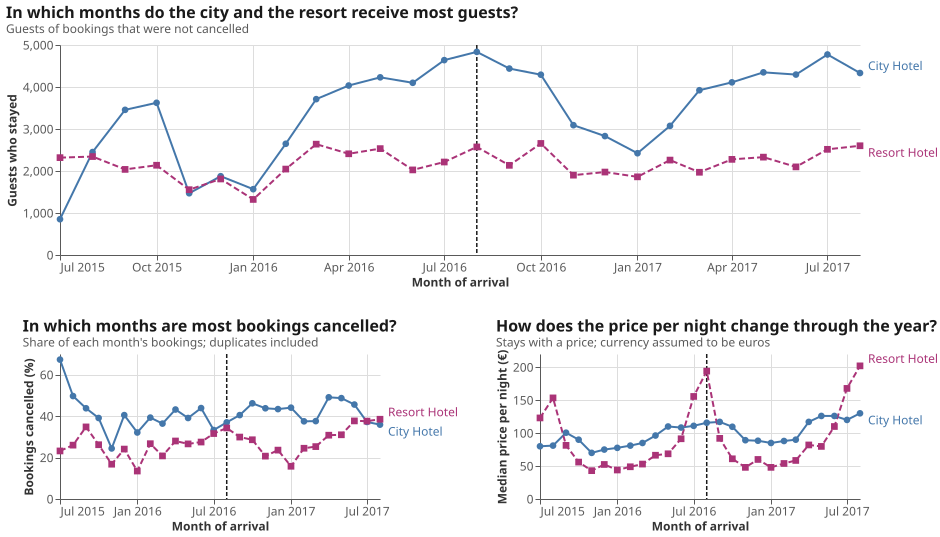

In [17]:
# ── Screen 1 as it will be laid out: C1 on top, C2 and C3 below ──────────────
# Shown with the month of August 2016 linked, to check that the rule appears in the three charts.
# (In the notebook the three charts share one set of parameters; on the page each chart is a separate
# embed and the page passes the values between them, task 6.5.)
p1, p2, p3 = screen_1_charts(pointer=False)
linked_example = alt.param(name='linked_month', value='2016-08')
screen_1 = alt.vconcat(p1, alt.hconcat(p2, p3, spacing=40), spacing=30).add_params(*FILTER_PARAMS, linked_example)
dashboard_style(with_values(screen_1))

### Decision: encoding of the monthly charts

**Context:** Natalia (deuteranopia) must tell the two hotels apart in three charts and relate the same month across them.

**Decision taken:** two hues of Paul Tol's bright palette, plus a different line style, a different point shape and a direct label for each hotel, so colour is never the only code. Points are kept on every month because they carry the tooltip, the `aria-label` and, in task 6.6, the keyboard focus. The y axes start at zero (honest scale, DRACO soft preference `zero_positional`). Lines, labels and the rule are hidden from screen readers (`aria=False`), so a screen reader meets only the points, each with a full sentence. The linked month is passed as a text key (`'2016-08'`), not as a time: while testing, the render engine and pandas turned the same month into times two hours apart (time zones), so the rule never matched.

**Alternatives considered:** a legend (rejected: it needs eye movement and memory, Part 4); points only on the hovered month (rejected: the keyboard needs a mark per month); y axes not starting at zero for the price (rejected: the price lines are far from zero, but DRACO's `zero_skew` only applies when the range is smaller than the distance to zero, which is not the case here).

> ⚠️ **Limitation:** the currency of `adr` is not stated in the paper; the charts say "currency assumed to be euros" (Part 1). The x axes of C2 and C3 are narrower than C1's, so a month is at the same relative place, not at the same pixel.

In [18]:
# ── Check 1: DRACO hard rules of C1, C2 and C3 ───────────────────────────────
draco_rows = []
for name, chart in [('C1', c1), ('C2', c2), ('C3', c3)]:
    draco_rows += draco_hard_rules(name, chart, month_hotel)
draco_checks = pd.DataFrame(draco_rows)
print(f'{len(draco_checks)} rule checks on {draco_checks["chart"].nunique()} charts | all pass: {draco_checks["passes"].all()}')
draco_checks.pivot_table(index='hard rule', columns='chart', values='passes', aggfunc='all')

105 rule checks on 3 charts | all pass: True


chart,C1,C2,C3
hard rule,,,
color_with_cardinality_gt_twenty: 2 colours,True,True,True
enc_type_valid: x temporal on a date field,True,True,True
enc_type_valid: y quantitative on a numeric field,True,True,True
line_area_with_discrete: x and y not both discrete,True,True,True
line_area_without_x_y: has x and y,True,True,True
"no log scale (log_q, area_bar_with_log)",True,True,True
no_encodings: at least one encoding,True,True,True
point_tick_bar_without_x_or_y: has x or y,True,True,True
same_field_x_and_y: different fields,True,True,True


In [19]:
# ── Check 2: the numbers drawn equal the pandas table, for all 12 filter combinations ─
# Each chart is rendered by Vega (vl-convert) with the filters set as the page will set them. The aria-label
# of every point drawn is compared with a sentence written by pandas from month_hotel.
WORDS = {'guests': ('{:,}', 'guests'), 'cancel_rate': ('{:.1f}', '% of bookings cancelled'),
         'median_price': ('{:,.1f}', 'euros per night (median)')}
CHART_FIELDS = {'c1': 'guests', 'c2': 'cancel_rate', 'c3': 'median_price'}


def drawn_points(spec, hotel, year):
    """Sentences of the points Vega draws for one filter combination."""
    svg = vlc.vegalite_to_svg(with_params(spec, {'hotel_filter': hotel, 'year_filter': year}))
    return sorted(label for label in re.findall(r'aria-label="([^"]*)"', svg) if ' Hotel, ' in label)


def expected_points(field, hotel, year):
    """The same sentences written by pandas from the aggregated table."""
    number_format, words = WORDS[field]
    rows = filtered(month_hotel, hotel, year)
    return sorted(f"{row.hotel}, {row.arrival_month:%B %Y}: {number_format.format(getattr(row, field))} {words}"
                  for row in rows.itertuples())


value_checks = []
for name, field in CHART_FIELDS.items():
    for hotel in HOTEL_FILTERS:
        for year in YEAR_FILTERS:
            drawn, expected = drawn_points(SCREEN_1_SPECS[name], hotel, year), expected_points(field, hotel, year)
            value_checks.append({'chart': name.upper(), 'hotel filter': hotel, 'year filter': str(year),
                                 'points drawn': len(drawn), 'points expected': len(expected),
                                 'same values': drawn == expected})
value_checks = pd.DataFrame(value_checks)
print(f'{len(value_checks)} renders | points compared: {value_checks["points drawn"].sum():,} | '
      f'all equal to pandas: {value_checks["same values"].all()}')
value_checks.head(12)

36 renders | points compared: 624 | all equal to pandas: True


,chart,hotel filter,year filter,points drawn,points expected,same values
0,C1,Both,All,52,52,True
1,C1,Both,2015,12,12,True
2,C1,Both,2016,24,24,True
3,C1,Both,2017,16,16,True
4,C1,City Hotel,All,26,26,True
5,C1,City Hotel,2015,6,6,True
6,C1,City Hotel,2016,12,12,True
7,C1,City Hotel,2017,8,8,True
8,C1,Resort Hotel,All,26,26,True
9,C1,Resort Hotel,2015,6,6,True


In [20]:
# ── Check 3: size of each chart against its slot of the layout grid, and the linked-month rule ─
SLOTS = {'c1': (960, 300), 'c2': (472, 244), 'c3': (472, 244)}     # Part 4 layout grid, px


def rule_lines(svg):
    """Number of visible lines of the linked-month rule layer (the rules of the other months have opacity 0)."""
    group = re.search(r'<g class="mark-rule role-mark[^"]*"[^>]*?(/?)>', svg)
    if group is None or group.group(1) == '/':
        return 0
    lines = re.findall(r'<line[^>]*>', svg[group.end():svg.index('</g>', group.end())])
    return sum(1 for line in lines if 'opacity="0"' not in line)


size_checks = []
for name, spec in SCREEN_1_SPECS.items():
    svg = vlc.vegalite_to_svg(with_params(spec, {'linked_month': '2016-08'}))
    width, height = (int(v) for v in re.search(r'<svg[^>]*width="(\d+)" height="(\d+)"', svg).groups())
    no_rule = vlc.vegalite_to_svg(with_params(spec, {}))
    size_checks.append({'chart': name.upper(), 'width px': width, 'height px': height,
                        'slot': f'{SLOTS[name][0]} x {SLOTS[name][1]}',
                        'fits': width <= SLOTS[name][0] and height <= SLOTS[name][1],
                        'rule lines, August 2016 linked': rule_lines(svg),
                        'rule lines, no month linked': rule_lines(no_rule)})
size_checks = pd.DataFrame(size_checks)
size_checks

,chart,width px,height px,slot,fits,"rule lines, August 2016 linked","rule lines, no month linked"
0,C1,940,293,960 x 300,True,1,0
1,C2,443,224,472 x 244,True,1,0
2,C3,450,224,472 x 244,True,1,0


**Finding:** C1, C2 and C3 pass every DRACO hard rule that applies to their layers (line, point, text and rule), and for all 12 hotel × year combinations every point Vega draws carries exactly the value pandas computed. Each chart fits its slot of the Part 4 grid, and the dashed rule is drawn once when a month is linked and not at all otherwise.

DRACO soft preferences: the quantitative measure is on y (position, the most accurate channel), time is on x, nothing is binned, the hotel (2 values) is on colour, line style and shape (cardinality well under 5), and the only text channel carries the hotel name (nominal), never a number. The line mark on a temporal x is DRACO's normal choice for an explicit time order.

### 5.3 Screen 2 (detail screen): C4 and C6, and behind "Show more" C7, C8 and the map C5

The detail screen answers Q2 and Q3 with C4 and C6; Q4, Q6 and the map wait behind "Show more" (Part 4). These charts share:

- the **selected country** (I7, default Portugal): its bars are dark orange with a black outline and its axis label is bold and darker; in C6 it is the orange line, and on the map its outline. So the selection is shown by colour, outline, weight of the label and, on the page, a text line (task 6.5);
- the **sort order** (I9) of the country bars, by guests or alphabetical, with "Other" always last;
- the hotel and year filters (I1, I2). C7 and C8 read medians precomputed for each filter combination (task 6.1), because medians cannot be added up after filtering.

In [21]:
# ── Shared parts of the screen 2 charts ───────────────────────────────────────
BAR_COLOUR = '#1F4E79'          # dark blue, 8.66:1 on white (Part 4)
SELECTED_COLOUR = '#B35900'     # dark orange, 4.83:1 on white (checked below with simulated deuteranopia)
ALL_GUESTS_COLOUR = TEXT_SECONDARY   # grey #595959, 7.0:1
OUTLINE = TEXT_MAIN

selected_country = alt.param(name='selected_country', value='Portugal')   # a country group: top 10 or 'Other'
sort_order = alt.param(name='sort_order', value='guests')                 # 'guests' or 'alphabetical'
# A click on a bar: read by the page, which then sets selected_country in every chart of the screen
clicked_country = alt.selection_point(name='clicked_country', fields=['country_group'], on='click', empty=False)

MEDIANS_FILTER = 'datum.hotel_filter == hotel_filter && datum.year_filter == year_filter'
# Sort key of the country bars: most guests first, or alphabetical; 'Other' is always last
SORT_KEY = ("datum.country_group == 'Other' ? (sort_order == 'guests' ? 1e12 : '~') : "
            "(sort_order == 'guests' ? -datum.country_guests : datum.country_group)")
IS_SELECTED = 'datum.country_group == selected_country'


def country_axis():
    """Country names on y, sorted by the toggle; the selected country's label is bold and darker."""
    return alt.Y('country_group:N', sort=alt.EncodingSortField(field='sort_key', op='min'),
                 axis=alt.Axis(title=None, labelLimit=150, labelFontSize=12,
                               labelFontWeight=alt.expr("datum.value == selected_country ? 'bold' : 'normal'"),
                               labelColor=alt.expr(f"datum.value == selected_country ? '{TEXT_MAIN}' : '{TEXT_SECONDARY}'")))


def bar_highlight():
    """Fill and outline of a bar: orange with a black outline if it is the selected country."""
    return dict(color=alt.when(IS_SELECTED).then(alt.value(SELECTED_COLOUR)).otherwise(alt.value(BAR_COLOUR)),
                stroke=alt.when(IS_SELECTED).then(alt.value(OUTLINE)).otherwise(alt.value(None)))


def js_fixed(number, digits):
    """A number with a fixed number of decimals, rounded as JavaScript (and so Vega) rounds."""
    return str(Decimal(float(number)).quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


def js_trimmed(number):
    """Vega's '.1~f' format: one decimal, without a trailing zero (3 nights, 2.5 nights)."""
    return js_fixed(number, 1).rstrip('0').rstrip('.')

print('Sort key:', SORT_KEY)

Sort key: datum.country_group == 'Other' ? (sort_order == 'guests' ? 1e12 : '~') : (sort_order == 'guests' ? -datum.country_guests : datum.country_group)


In [22]:
# ── C4: guests by country, one panel per hotel (Q2) ──────────────────────────

def c4_chart(clickable=True):
    base = alt.Chart(alt.NamedData(name='country_month')).transform_filter(FILTER_EXPRESSION).transform_aggregate(
        guests='sum(guests)', groupby=['country_group', 'hotel']
    ).transform_joinaggregate(hotel_guests='sum(guests)', groupby=['hotel']
    ).transform_joinaggregate(country_guests='sum(guests)', groupby=['country_group']
    ).transform_calculate(
        share='100 * datum.guests / datum.hotel_guests', sort_key=SORT_KEY,
        bar_text="datum.country_group + ', ' + datum.hotel + ': ' + format(datum.share, '.1f') + "
                 "' % of the guests of the hotel (' + format(datum.guests, ',d') + ' guests)'")
    bars = base.mark_bar(strokeWidth=2).encode(
        y=country_axis(),
        x=alt.X('share:Q', title="% of the hotel's guests", axis=alt.Axis(format='d')),
        description=alt.Description('bar_text:N'),
        tooltip=[alt.Tooltip('country_group:N', title='Country'), alt.Tooltip('hotel:N', title='Hotel'),
                 alt.Tooltip('share:Q', title='Share of the guests of the hotel (%)', format='.1f'),
                 alt.Tooltip('guests:Q', title='Guests', format=',d')],
        # One panel per hotel, as a column encoding (not .facet()) so the totals above are computed on all rows
        # before the panels are made; with .facet() each panel sorted the countries by its own guests
        column=alt.Column('hotel:N', title=None, spacing=16,
                          header=alt.Header(labelFontSize=13, labelColor=TEXT_MAIN, labelFontWeight=600, labelAnchor='start')),
        **bar_highlight()).properties(width=175, height=330)
    if clickable:
        bars = bars.add_params(clicked_country)
    return bars.properties(title=alt.TitleParams('Which countries do the guests come from?',
                                       subtitle='Top 10 countries by guests, and Other'),
                 description='Bar chart of the share of guests from each of the ten main countries and Other, '
                             'one panel per hotel, with the selected country highlighted.')

c4 = c4_chart()
print('C4 built')

C4 built


In [23]:
# ── C6: season of the selected country against all guests (Q3) ───────────────
SERIES = ['Selected country', 'All guests']
SERIES_COLOURS = alt.Scale(domain=SERIES, range=[SELECTED_COLOUR, ALL_GUESTS_COLOUR])
SERIES_DASHES = alt.Scale(domain=SERIES, range=[[1, 0], [6, 3]])
SERIES_SHAPES = alt.Scale(domain=SERIES, range=['circle', 'square'])


def c6_chart():
    # Each booking row counts for "All guests" and, if it is from the selected country, also for that country
    base = alt.Chart(alt.NamedData(name='country_month')).transform_filter(FILTER_EXPRESSION).transform_calculate(
        all_key="'All guests'", selected_key=f"{IS_SELECTED} ? 'Selected country' : null"
    ).transform_fold(['all_key', 'selected_key'], as_=['key', 'series']).transform_filter('datum.series != null'
    ).transform_aggregate(guests='sum(guests)', groupby=['calendar_month', 'series']
    ).transform_joinaggregate(series_guests='sum(guests)', groupby=['series']
    ).transform_calculate(
        share='100 * datum.guests / datum.series_guests',
        month_date='datetime(2001, datum.calendar_month - 1, 1)',     # any year: only the month is shown
        series_name="datum.series == 'Selected country' ? selected_country : 'All guests'",
        point_text="datum.series_name + ', ' + timeFormat(datum.month_date, '%B') + ': ' + format(datum.share, '.1f') + "
                   "' % of the guests of the group (' + format(datum.guests, ',d') + ' guests)'"
    ).encode(x=alt.X('month_date:T', title='Month of arrival (all years together)',
                     axis=alt.Axis(format='%b', labelAngle=0, tickCount={'interval': 'month', 'step': 1})))
    y = alt.Y('share:Q', title='Share of the guests of the group (%)', axis=alt.Axis(format='d'))
    colour = alt.Color('series:N', scale=SERIES_COLOURS, legend=None)

    lines = base.mark_line(strokeWidth=2.5, aria=False).encode(
        y=y, color=colour, strokeDash=alt.StrokeDash('series:N', scale=SERIES_DASHES, legend=None))
    points = base.mark_point(filled=True, size=45, opacity=1).encode(
        y=y, color=colour, shape=alt.Shape('series:N', scale=SERIES_SHAPES, legend=None),
        description=alt.Description('point_text:N'),
        tooltip=[alt.Tooltip('month_date:T', title='Month', format='%B'), alt.Tooltip('series_name:N', title='Group'),
                 alt.Tooltip('share:Q', title='Share of the guests of the group (%)', format='.1f'),
                 alt.Tooltip('guests:Q', title='Guests', format=',d')])
    labels = base.transform_joinaggregate(last_month='max(month_date)', groupby=['series']).transform_filter(
        'time(datum.month_date) == time(datum.last_month)'
    ).transform_joinaggregate(series_shown='count()').transform_window(
        rank_at_end='rank()', sort=[alt.SortField('share', order='descending')]
    ).transform_calculate(label_shift='datum.series_shown == 1 ? 0 : (datum.rank_at_end == 1 ? -7 : 7)'
    ).mark_text(align='left', dx=8, dy=alt.expr('datum.label_shift'), fontSize=12, aria=False).encode(
        y=y, text='series_name:N', color=colour)
    return alt.layer(lines, points, labels).properties(
        width=250, height=330, description='Line chart of the share of guests in each calendar month, '
                                           'for the selected country and for all guests.',
        title=alt.TitleParams('When does the selected market travel?',
                              subtitle='Guests per calendar month, as % of the group'))

c6 = c6_chart()
print('C6 built')

C6 built


In [24]:
# ── C7 and C8: median nights and median booking advance per country (Q4, Q6) ─

def median_bars(field, axis_title, words, title, subtitle, description, clickable=True):
    base = alt.Chart(alt.NamedData(name='country_medians')).transform_filter(MEDIANS_FILTER).transform_calculate(
        country_guests='datum.guests', sort_key=SORT_KEY,
        bar_text=f"datum.country_group + ': ' + format(datum.{field}, '.1~f') + ' {words}'")
    bars = base.mark_bar(strokeWidth=2).encode(
        y=country_axis(),
        x=alt.X(f'{field}:Q', title=axis_title, axis=alt.Axis(format='d')),
        description=alt.Description('bar_text:N'),
        tooltip=[alt.Tooltip('country_group:N', title='Country'),
                 alt.Tooltip(f'{field}:Q', title=axis_title, format='.1~f'),
                 alt.Tooltip('guests:Q', title='Guests', format=',d')],
        **bar_highlight())
    if clickable:
        bars = bars.add_params(clicked_country)
    return bars.properties(width=310, height=250, description=description,
                           title=alt.TitleParams(title, subtitle=subtitle))


def screen_2_bars(clickable=True):
    c7 = median_bars('median_nights', 'Median nights per stay', 'nights (median)',
                     'How long do guests from each market stay?', 'Stays: bookings that were not cancelled',
                     'Bar chart of the median number of nights per stay for each country, with the selected country highlighted.',
                     clickable)
    c8 = median_bars('median_lead_time', 'Median days from booking to arrival', 'days in advance (median)',
                     'How far in advance does each market book?', 'Stays: bookings that were not cancelled',
                     'Bar chart of the median number of days between booking and arrival for each country, '
                     'with the selected country highlighted.', clickable)
    return c7, c8

c7, c8 = screen_2_bars()
print('C7 and C8 built')

C7 and C8 built


In [25]:
# ── C5: small world map of guests per country (Q2) ───────────────────────────
WORLD_COUNTRIES = alt.NamedData(name='world', format=alt.DataFormat(type='topojson', feature='countries'))
ANTARCTICA = 10                                                        # ISO numeric code; 2 guests, but it takes a sixth of the map
MAP_CLASSES = ['1 to 9', '10 to 99', '100 to 999', '1,000 to 9,999', '10,000 or more']   # guests per country
MAP_BLUES = ['#C6DBEF', '#9ECAE1', '#6BAED6', '#3182BD', '#08519C']   # light to dark: few to many guests
NO_GUESTS = '#EEEEEE'


def c5_chart():
    background = alt.Chart(WORLD_COUNTRIES).transform_filter(f'datum.id != {ANTARCTICA}').mark_geoshape(
        fill=NO_GUESTS, stroke='#FFFFFF', strokeWidth=0.5, aria=False)
    countries = alt.Chart(alt.NamedData(name='country_map')).transform_filter(
        f'{FILTER_EXPRESSION} && datum.iso_numeric != {ANTARCTICA}').transform_aggregate(
        guests='sum(guests)', groupby=['iso_numeric', 'country_name']
    ).transform_lookup(lookup='iso_numeric', from_=alt.LookupData(data=WORLD_COUNTRIES, key='id'), as_='geo'
    ).transform_filter('isValid(datum.geo)').transform_calculate(
        map_text="datum.country_name + ': ' + format(datum.guests, ',d') + ' guests'",
        # Five classes, one per power of ten, so the legend can name each class in words
        guest_class=("datum.guests < 10 ? '1 to 9' : datum.guests < 100 ? '10 to 99' : datum.guests < 1000 ? "
                     "'100 to 999' : datum.guests < 10000 ? '1,000 to 9,999' : '10,000 or more'")
    ).mark_geoshape().encode(
        shape='geo:G',
        color=alt.Color('guest_class:O', scale=alt.Scale(domain=MAP_CLASSES, range=MAP_BLUES),
                        legend=alt.Legend(title='Guests per country', orient='right', labelLimit=200,
                                          symbolType='square', symbolSize=200, labelFontSize=12, titleFontSize=12)),
        stroke=alt.when('datum.country_name == selected_country').then(alt.value(OUTLINE)).otherwise(alt.value('#FFFFFF')),
        strokeWidth=alt.when('datum.country_name == selected_country').then(alt.value(2)).otherwise(alt.value(0.5)),
        description=alt.Description('map_text:N'),
        tooltip=[alt.Tooltip('country_name:N', title='Country'), alt.Tooltip('guests:Q', title='Guests', format=',d')])
    return alt.layer(background, countries).project(type='equalEarth').properties(
        width=620, height=300, description='World map of the number of guests from each country, in five classes.',
        title=alt.TitleParams('Where do the guests come from?',
                              subtitle='Guests per country; grey: no guests; very small countries are not drawn'))

c5 = c5_chart()
print('C5 built')

C5 built


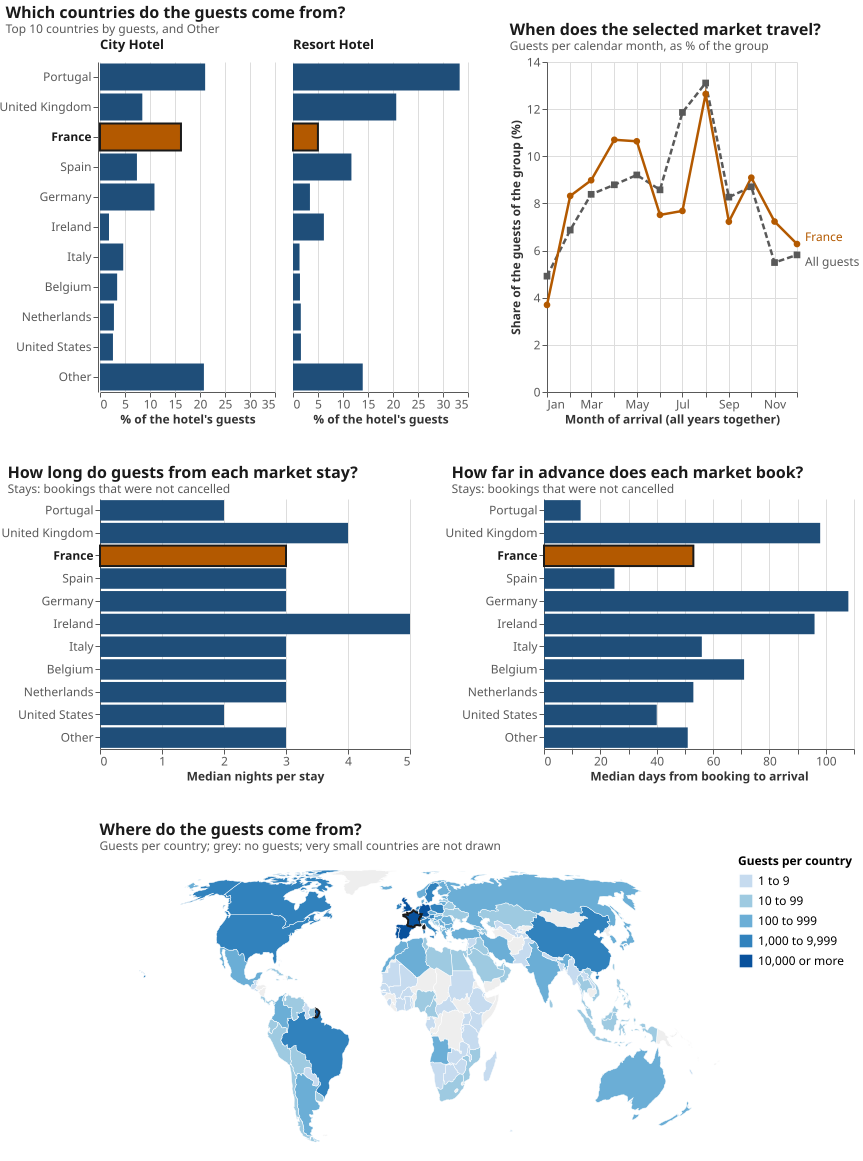

In [26]:
# ── Specs of screen 2 for the page, and the screen as it will be laid out ────
warnings.filterwarnings('ignore', message='Automatically deduplicated selection parameter')
SCREEN_2_SPECS = {
    'c4': dashboard_style(c4.add_params(*FILTER_PARAMS, selected_country, sort_order)).to_dict(),
    'c6': dashboard_style(c6.add_params(*FILTER_PARAMS, selected_country)).to_dict(),
    'c7': dashboard_style(c7.add_params(*FILTER_PARAMS, selected_country, sort_order)).to_dict(),
    'c8': dashboard_style(c8.add_params(*FILTER_PARAMS, selected_country, sort_order)).to_dict(),
    'c5': dashboard_style(c5.add_params(*FILTER_PARAMS, selected_country)).to_dict(),
}
# Shown with France selected, to check that the selection reaches every chart. Altair 6.2 cannot add
# parameters to this concatenation (an internal naming error), so they are added to the spec directly.
p7, p8 = screen_2_bars(clickable=False)
screen_2 = alt.vconcat(alt.hconcat(c4_chart(clickable=False), c6_chart(), spacing=40),
                       alt.hconcat(p7, p8, spacing=40), c5_chart(), spacing=40
                       ).resolve_scale(color='independent')   # C6 and the map have different colour scales
screen_2_preview = dashboard_style(screen_2).to_dict()
screen_2_preview['params'] = [{'name': 'hotel_filter', 'value': 'Both'}, {'name': 'year_filter', 'value': 'All'},
                              {'name': 'selected_country', 'value': 'France'}, {'name': 'sort_order', 'value': 'guests'}]
screen_2_preview['datasets'] = DATASETS
SVG(vlc.vegalite_to_svg(screen_2_preview))

### Decision: encoding of the detail charts

**Context:** Natalia compares the mix of markets of the two destinations (Q2) and follows one market at a time (Q3, Q4, Q6); she has deuteranopia.

**Decision taken:** bars in one dark blue, sorted, starting at zero, with the hotels in two panels that share the country axis, so the two mixes are compared by position (Part 4). C4 shows each country's **share of the hotel's guests**, so a small and a large hotel can be compared. The selected country is dark orange (`#B35900`): orange and blue stay far apart with deuteranopia, and the outline and bold label repeat the selection without colour. C6 compares the selected country (orange, solid, circles) with all guests (grey, dashed, squares), each as a percentage of its own year, so a small market and the total have the same scale. C7 and C8 keep the country order of C4 (by guests or alphabetical, as planned for the sort toggle in Part 5), so a country is found in the same place in the three bar charts. The map uses an equal-area projection (Equal Earth), because Mercator would enlarge the northern countries where most guests come from, and five classes of a sequential blue, one per power of ten, named in words in the legend (GeoHandout; DRACO has no rules for maps).

**Alternatives considered:** sorting C7 and C8 by their own value (rejected for the same country order everywhere; the "Alphabetical" option also helps); counts instead of shares in C4 (rejected: the city hotel has more guests, so its bars would always be longer); a continuous colour scale on the map (rejected: Portugal has about 300 times the guests of most countries, so nearly every country would look the same).

> ⚠️ **Limitation:** "Other" (all other countries and unknown) is a group, not a country, so its medians mix many markets. On the map, colour is the only code for the number of guests (the pattern rules keep quantitative maps without patterns); the tooltip and the data table of task 6.7 give the numbers. Very small countries (for example Singapore, Malta, Gibraltar) are not in the 1:110 million map, and Antarctica (2 guests) is left out to give the map more room, so they are not drawn (counted below).

In [27]:
# ── Check 1: DRACO hard rules of C4 to C8, and colour of the selection ───────
COMPUTED_C4 = {'share': ('number', None)}
COMPUTED_C5 = {'guest_class': ('text', 5)}
COMPUTED_C6 = {'share': ('number', None), 'month_date': ('date', 12), 'series': ('text', 2), 'series_name': ('text', 2)}
draco_rows_2 = (draco_hard_rules('C4', c4, country_month, COMPUTED_C4) + draco_hard_rules('C6', c6, country_month, COMPUTED_C6)
                + draco_hard_rules('C7', c7, country_medians) + draco_hard_rules('C8', c8, country_medians)
                + draco_hard_rules('C5 (map, outside DRACO)', c5, country_map, COMPUTED_C5))
draco_checks = pd.concat([draco_checks, pd.DataFrame(draco_rows_2)], ignore_index=True)
screen_2_draco = draco_checks[draco_checks['chart'].isin(['C4', 'C5 (map, outside DRACO)', 'C6', 'C7', 'C8'])]
print(f'{len(screen_2_draco)} rule checks on screen 2 | all pass: {screen_2_draco["passes"].all()} '
      f'| all charts so far: {draco_checks["passes"].all()}')
screen_2_draco.pivot_table(index='hard rule', columns='chart', values='passes', aggfunc='all').fillna('-')

68 rule checks on screen 2 | all pass: True | all charts so far: True


chart,C4,"C5 (map, outside DRACO)",C6,C7,C8
hard rule,,,,,
bar_area_without_zero: the continuous axis includes zero,True,-,-,True,True
bar_tick_continuous_x_y: not continuous on both x and y,True,-,-,True,True
color_with_cardinality_gt_twenty: 2 colours,-,-,True,-,-
color_with_cardinality_gt_twenty: 5 colours,-,True,-,-,-
column_no_x: column used with a x encoding,True,-,-,-,-
enc_type_valid: x quantitative on a numeric field,True,-,-,True,True
enc_type_valid: x temporal on a date field,-,-,True,-,-
enc_type_valid: y quantitative on a numeric field,-,-,True,-,-
line_area_with_discrete: x and y not both discrete,-,-,True,-,-


In [28]:
# ── Contrast of the new colours, and distance between them with simulated deuteranopia ─
# Same method as Part 4 (WCAG relative luminance; Machado et al. 2009 matrix, severity 1; CIELAB distance)
def linear_rgb(hex_colour):
    channels = pd.Series([int(hex_colour[i:i + 2], 16) / 255 for i in (1, 3, 5)])
    return channels.where(channels > 0.04045, channels / 12.92).where(channels <= 0.04045, ((channels + 0.055) / 1.055) ** 2.4)

def contrast(colour_a, colour_b='#FFFFFF'):
    lum = [0.2126 * c[0] + 0.7152 * c[1] + 0.0722 * c[2] for c in (linear_rgb(colour_a), linear_rgb(colour_b))]
    return (max(lum) + 0.05) / (min(lum) + 0.05)

DEUTERANOPIA = [[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]

def lab_deuteranopia(hex_colour):
    rgb = linear_rgb(hex_colour)
    sim = [min(max(sum(DEUTERANOPIA[r][c] * rgb[c] for c in range(3)), 0), 1) for r in range(3)]
    xyz = [sum(m * v for m, v in zip(row, sim)) for row in [[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]]]
    xyz = [v / w for v, w in zip(xyz, [0.95047, 1.0, 1.08883])]
    f = [v ** (1 / 3) if v > 0.008856 else 7.787 * v + 16 / 116 for v in xyz]
    return (116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2]))

def distance_deuteranopia(colour_a, colour_b):
    return sum((a - b) ** 2 for a, b in zip(lab_deuteranopia(colour_a), lab_deuteranopia(colour_b))) ** 0.5

colour_checks = pd.DataFrame([
    ('Selected country (bars, C6 line)', SELECTED_COLOUR, contrast(SELECTED_COLOUR), 'bar blue', distance_deuteranopia(SELECTED_COLOUR, BAR_COLOUR)),
    ('All guests (C6 line)', ALL_GUESTS_COLOUR, contrast(ALL_GUESTS_COLOUR), 'selected orange', distance_deuteranopia(ALL_GUESTS_COLOUR, SELECTED_COLOUR)),
    ('Bars', BAR_COLOUR, contrast(BAR_COLOUR), 'selected orange', distance_deuteranopia(BAR_COLOUR, SELECTED_COLOUR)),
], columns=['use', 'hex', 'contrast on white', 'compared with', 'CIELAB distance with deuteranopia']).round(2)
colour_checks['passes 3:1'] = colour_checks['contrast on white'] >= 3
colour_checks

,use,hex,contrast on white,compared with,CIELAB distance with deuteranopia,passes 3:1
0,"Selected country (bars, C6 line)",#B35900,4.83,bar blue,90.13,True
1,All guests (C6 line),#595959,7.00,selected orange,58.10,True
2,Bars,#1F4E79,8.66,selected orange,90.13,True


In [29]:
# ── Check 2: the numbers drawn equal pandas, for every filter combination ────

def drawn_labels(spec, params, pattern):
    """aria-labels of the marks Vega draws with some parameters set, keeping those that match a pattern."""
    svg = vlc.vegalite_to_svg(with_params(spec, params))
    return sorted(label for label in re.findall(r'aria-label="([^"]*)"', svg) if re.search(pattern, label))


def expected_c4(hotel, year):
    rows = filtered(country_month, hotel, year).groupby(['country_group', 'hotel'], as_index=False)['guests'].sum()
    rows['share'] = 100 * rows['guests'] / rows.groupby('hotel')['guests'].transform('sum')
    return sorted(f"{r.country_group}, {r.hotel}: {js_fixed(r.share, 1)} % of the guests of the hotel ({r.guests:,} guests)"
                  for r in rows.itertuples())


def expected_c6(hotel, year, country):
    rows = filtered(country_month, hotel, year)
    texts = []
    for name, group in [('All guests', rows), (country, rows[rows['country_group'] == country])]:
        per_month = group.groupby('calendar_month')['guests'].sum()
        for month, guests in per_month.items():
            share = 100 * guests / per_month.sum()
            texts.append(f"{name}, {calendar.month_name[month]}: {js_fixed(share, 1)} % of the guests of the group ({guests:,} guests)")
    return sorted(texts)


def expected_medians(field, words, hotel, year):
    rows = country_medians[(country_medians['hotel_filter'] == hotel) & (country_medians['year_filter'] == str(year))]
    return sorted(f"{r.country_group}: {js_trimmed(getattr(r, field))} {words}" for r in rows.itertuples())


world_ids = {country['id'] for country in WORLD['objects']['countries']['geometries']}

def expected_c5(hotel, year):
    rows = filtered(country_map, hotel, year).groupby(['iso_numeric', 'country_name'], as_index=False)['guests'].sum()
    rows = rows[rows['iso_numeric'].isin(world_ids) & (rows['iso_numeric'] != ANTARCTICA)]
    return sorted(f"{r.country_name}: {r.guests:,} guests" for r in rows.itertuples())


GROUPS = '|'.join(TOP_10 + ['Other'])
value_rows = []
for hotel in HOTEL_FILTERS:
    for year in YEAR_FILTERS:
        filters = {'hotel_filter': hotel, 'year_filter': year}
        cases = [('C4', drawn_labels(SCREEN_2_SPECS['c4'], filters, r'% of the guests of the hotel'), expected_c4(hotel, year)),
                 ('C7', drawn_labels(SCREEN_2_SPECS['c7'], filters, r'nights \(median\)$'),
                  expected_medians('median_nights', 'nights (median)', hotel, year)),
                 ('C8', drawn_labels(SCREEN_2_SPECS['c8'], filters, r'days in advance \(median\)$'),
                  expected_medians('median_lead_time', 'days in advance (median)', hotel, year)),
                 ('C5', drawn_labels(SCREEN_2_SPECS['c5'], filters, r'^[^;]*: [\d,]+ guests$'), expected_c5(hotel, year))]
        for country in ['Portugal', 'United Kingdom', 'Other']:
            cases.append((f'C6 ({country})', drawn_labels(SCREEN_2_SPECS['c6'], {**filters, 'selected_country': country},
                                                          r'% of the guests of the group'),
                          expected_c6(hotel, year, country)))
        for chart, drawn, expected in cases:
            value_rows.append({'chart': chart, 'hotel filter': hotel, 'year filter': str(year), 'points drawn': len(drawn),
                               'points expected': len(expected), 'same values': drawn == expected})
screen_2_values = pd.DataFrame(value_rows)
value_checks = pd.concat([value_checks, screen_2_values], ignore_index=True)
print(f'{len(screen_2_values)} renders | marks compared: {screen_2_values["points drawn"].sum():,} | '
      f'all equal to pandas: {screen_2_values["same values"].all()}')
screen_2_values.groupby('chart')[['points drawn', 'same values']].agg({'points drawn': 'sum', 'same values': 'all'})

84 renders | marks compared: 2,346 | all equal to pandas: True


,points drawn,same values
chart,,
C4,176,True
C5,1222,True
C6 (Other),228,True
C6 (Portugal),228,True
C6 (United Kingdom),228,True
C7,132,True
C8,132,True


In [30]:
# ── Check 3: selection and sort order ─────────────────────────────────────────

def axis_countries(svg):
    """Country names of the first y axis, in the order they are drawn (top to bottom)."""
    for group in re.findall(r'<g class="mark-text role-axis-label"[^>]*>(.*?)</g>', svg, flags=re.S):
        names = re.findall(r'>([^<]+)</text>', group)
        if names and set(names) <= set(TOP_10 + ['Other']):
            return names
    return []


guests_order = (country_month.groupby('country_group')['guests'].sum().drop('Other')
                .sort_values(ascending=False).index.tolist() + ['Other'])
alphabetical_order = sorted(TOP_10) + ['Other']
selection_rows = []
for name in ['c4', 'c7', 'c8']:
    for order, expected in [('guests', guests_order), ('alphabetical', alphabetical_order)]:
        svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS[name], {'sort_order': order}))
        selection_rows.append({'chart': name.upper(), 'check': f'order "{order}" (both hotels, all years)',
                               'passes': axis_countries(svg) == expected})
    for country, bars_expected in [('France', 2 if name == 'c4' else 1), ('Other', 2 if name == 'c4' else 1)]:
        svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS[name], {'selected_country': country}))
        selection_rows.append({'chart': name.upper(), 'check': f'{country} selected: orange bars = {bars_expected}',
                               'passes': svg.count(f'fill="{SELECTED_COLOUR}"') == bars_expected})
svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS['c6'], {'selected_country': 'France'}))
selection_rows.append({'chart': 'C6', 'check': 'France selected: orange line and label "France"',
                       'passes': f'stroke="{SELECTED_COLOUR}"' in svg and '>France</text>' in svg})
svg = vlc.vegalite_to_svg(with_params(SCREEN_2_SPECS['c5'], {'selected_country': 'France'}))
selection_rows.append({'chart': 'C5', 'check': 'France selected: one country outlined',
                       'passes': svg.count('stroke-width="2"') == 1})
selection_checks = pd.DataFrame(selection_rows)
print('All selection and sort checks pass:', selection_checks['passes'].all())
selection_checks

All selection and sort checks pass: True


,chart,check,passes
0,C4,"order ""guests"" (both hotels, all years)",True
1,C4,"order ""alphabetical"" (both hotels, all years)",True
2,C4,France selected: orange bars = 2,True
3,C4,Other selected: orange bars = 2,True
4,C7,"order ""guests"" (both hotels, all years)",True
5,C7,"order ""alphabetical"" (both hotels, all years)",True
6,C7,France selected: orange bars = 1,True
7,C7,Other selected: orange bars = 1,True
8,C8,"order ""guests"" (both hotels, all years)",True
9,C8,"order ""alphabetical"" (both hotels, all years)",True


In [31]:
# ── Check 4: size of each chart, and what the map cannot draw ────────────────

# Slots: C4 and C6 from the Part 4 grid; the "Show more" area (960 px wide) is laid out here
SLOTS_2 = {'c4': (520, 500), 'c6': (424, 500), 'c7': (472, 340), 'c8': (472, 340), 'c5': (960, 420)}
size_rows = []
for name, spec in SCREEN_2_SPECS.items():
    svg = vlc.vegalite_to_svg(with_params(spec, {}))
    width, height = (int(v) for v in re.search(r'<svg[^>]*width="(\d+)" height="(\d+)"', svg).groups())
    size_rows.append({'chart': name.upper(), 'width px': width, 'height px': height,
                      'slot': f'{SLOTS_2[name][0]} x {SLOTS_2[name][1]}',
                      'fits': width <= SLOTS_2[name][0] and height <= SLOTS_2[name][1]})
size_checks = pd.concat([size_checks, pd.DataFrame(size_rows)], ignore_index=True)

# Countries and guests the map cannot draw (too small for the 1:110 million map)
not_drawn = country_map[~country_map['iso_numeric'].isin(world_ids) | (country_map['iso_numeric'] == ANTARCTICA)]
print(f"Not drawn on the map: {not_drawn['country'].nunique()} countries (Antarctica and very small ones), "
      f"{not_drawn['guests'].sum():,} guests ({100 * not_drawn['guests'].sum() / country_map['guests'].sum():.2f} % "
      f"of the guests with a known country)")
pd.DataFrame(size_rows)

Not drawn on the map: 29 countries (Antarctica and very small ones), 190 guests (0.13 % of the guests with a known country)


,chart,width px,height px,slot,fits
0,C4,474,431,520 x 500,True
1,C6,359,413,424 x 500,True
2,C7,414,328,472 x 340,True
3,C8,414,328,472 x 340,True
4,C5,760,344,960 x 420,True


**Finding:** C4, C6, C7 and C8 pass every DRACO hard rule that applies (C4's hotel panels included); the map only has the general rules, as DRACO has none for maps. For every filter combination, and in C6 for three different selected groups, every bar, point and country Vega draws carries exactly the value pandas computed. The selection reaches every chart, the sort toggle gives the expected orders, and every chart fits its space.

DRACO soft preferences: the measures are on position (x for bars, y for lines); the country axis has 11 values, under the soft limit of 12; bars are sorted; nothing is binned; the two series of C6 use colour, line style and shape (2 values each). C6 uses the month as a time unit on a temporal axis, not as a category, so the line is not on a discrete axis (Part 4).

## 6. Export

In [32]:
# ── Export the aggregated tables to data/processed ───────────────────────────
tables = {'dashboard_month_hotel.csv': month_hotel, 'dashboard_country_month.csv': country_month,
          'dashboard_country_map.csv': country_map, 'dashboard_filter_kpis.csv': filter_kpis,
          'dashboard_country_medians.csv': country_medians}
for file_name, table in tables.items():
    table.to_csv(PROCESSED_DIR / file_name, index=False)
checks.to_csv(OUTPUT_DIR / 'table_checks.csv', index=False)
top_10_table.to_csv(OUTPUT_DIR / 'top_10_countries.csv')

# Read them back to check that they load, with their size
pd.DataFrame([(name, len(pd.read_csv(PROCESSED_DIR / name)), round((PROCESSED_DIR / name).stat().st_size / 1024, 1))
              for name in tables], columns=['file', 'rows', 'KB'])

,file,rows,KB
0,dashboard_month_hotel.csv,52,3.0
1,dashboard_country_month.csv,569,21.2
2,dashboard_country_map.csv,586,21.1
3,dashboard_filter_kpis.csv,12,0.8
4,dashboard_country_medians.csv,132,6.1


In [33]:
# ── Export the chart checks and a preview image of the charts of each screen ─
draco_checks.to_csv(OUTPUT_DIR / 'draco_checks.csv', index=False)
value_checks.to_csv(OUTPUT_DIR / 'chart_value_checks.csv', index=False)
size_checks.to_csv(OUTPUT_DIR / 'chart_size_checks.csv', index=False)
selection_checks.to_csv(OUTPUT_DIR / 'selection_sort_checks.csv', index=False)
colour_checks.to_csv(OUTPUT_DIR / 'selected_colour_checks.csv', index=False)
for file_name, preview in [('screen_1_charts.png', dashboard_style(with_values(screen_1)).to_dict()),
                           ('screen_2_charts.png', screen_2_preview)]:
    (OUTPUT_DIR / file_name).write_bytes(vlc.vegalite_to_png(preview, scale=2))
sorted(path.name for path in OUTPUT_DIR.iterdir())

['chart_size_checks.csv',
 'chart_value_checks.csv',
 'draco_checks.csv',
 'export_checks.csv',
 'screen_1_charts.png',
 'screen_2_charts.png',
 'selected_colour_checks.csv',
 'selection_sort_checks.csv',
 'table_checks.csv',
 'top_10_countries.csv']

In [34]:
# ── Export data.js and specs.js for the dashboard pages (task 6.4) ───────────
# The pages load these two files with <script src>, so they open by double-click with no server
# (architecture.md). Only the columns that the charts and the KPIs use are kept.
DASHBOARD_TABLES = {
    'month_hotel': month_hotel[['arrival_month', 'hotel', 'year', 'bookings', 'cancelled', 'stays', 'guests',
                                'cancel_rate', 'median_price']],
    'country_month': country_month[['country_group', 'hotel', 'year', 'calendar_month', 'guests']],
    'country_medians': country_medians,
    'country_map': country_map[['iso_numeric', 'country_name', 'hotel', 'year', 'guests']].astype({'iso_numeric': int}),
    'filter_kpis': filter_kpis,
}
dashboard_data = {name: records(table) for name, table in DASHBOARD_TABLES.items()}
dashboard_data['world'] = WORLD
dashboard_specs = {**SCREEN_1_SPECS, **SCREEN_2_SPECS}


def write_js(path, variable, value, what):
    """Write a value as a JavaScript constant (JSON), so a page can load it with <script src>."""
    text = (f'// {what}\n// Written by Part 6/code/build_dashboard.ipynb; do not edit by hand.\n'
            f'const {variable} = {json.dumps(value, ensure_ascii=False, separators=(",", ":"), allow_nan=False)};\n')
    path.write_text(text, encoding='utf-8')
    return path


write_js(DASHBOARD_DIR / 'data.js', 'DASHBOARD_DATA', dashboard_data,
         'Aggregated data of the hotel bookings dashboard and the world map (TopoJSON).')
write_js(DASHBOARD_DIR / 'specs.js', 'DASHBOARD_SPECS', dashboard_specs,
         'Vega-Lite specs of the dashboard charts; their named datasets are in data.js.')
pd.DataFrame([(path.name, round(path.stat().st_size / 1024, 1)) for path in [DASHBOARD_DIR / 'data.js', DASHBOARD_DIR / 'specs.js']],
             columns=['file', 'KB'])

,file,KB
0,data.js,255.1
1,specs.js,32.7


In [35]:
# ── Check: the exported files give the same charts as the notebook ───────────
# Each spec is read back from specs.js, given only the columns kept in data.js, and drawn by Vega;
# the aria-labels of its marks must be the same as with the full tables used in the checks above.

def read_js(path, variable):
    text = path.read_text(encoding='utf-8')
    return json.loads(text.split(f'const {variable} = ', 1)[1].rstrip().rstrip(';'))


exported_data = read_js(DASHBOARD_DIR / 'data.js', 'DASHBOARD_DATA')
exported_specs = read_js(DASHBOARD_DIR / 'specs.js', 'DASHBOARD_SPECS')
export_rows = []
for name, spec in exported_specs.items():
    full = vlc.vegalite_to_svg(with_params(spec, {}))
    reduced = json.loads(json.dumps(spec))
    reduced['datasets'] = exported_data
    reduced = vlc.vegalite_to_svg(reduced)
    labels = lambda svg: sorted(re.findall(r'aria-label="([^"]*)"', svg))
    export_rows.append({'chart': name.upper(), 'marks with a label': len(labels(reduced)),
                        'same as in the notebook': labels(full) == labels(reduced)})
export_checks = pd.DataFrame(export_rows)
print('Charts in specs.js:', len(exported_specs), '| datasets in data.js:', sorted(exported_data),
      '| all the same:', export_checks['same as in the notebook'].all())
export_checks.to_csv(OUTPUT_DIR / 'export_checks.csv', index=False)
export_checks

Charts in specs.js: 8 | datasets in data.js: ['country_map', 'country_medians', 'country_month', 'filter_kpis', 'month_hotel', 'world'] | all the same: True


,chart,marks with a label,same as in the notebook
0,C1,56,True
1,C2,56,True
2,C3,56,True
3,C4,29,True
4,C6,28,True
5,C7,15,True
6,C8,15,True
7,C5,139,True


### Decision: how the pages get the data, the specs and the libraries

**Context:** the dashboard must open by double-click, with no server and no internet (architecture.md); browsers block `fetch` of a local `.json` file.

**Decision taken:** the notebook writes `data.js` (`const DASHBOARD_DATA = {...}`, about 255 KB, world map included) and `specs.js` (`const DASHBOARD_SPECS = {...}`), loaded with `<script src>`. Each spec keeps its named datasets, and the page adds their values before drawing (`dashboard.js`). The libraries are local copies from npm: Vega 6.2.0, Vega-Lite 6.4.1 (the version Altair 6.2.2 writes) and vega-embed 7.1.0, with their BSD-3-Clause licences, in `dashboard/lib/`. The page style and code shared by both screens are in `dashboard.css` and `dashboard.js`, so the two screens cannot drift apart.

**Alternatives considered:** one HTML file with the data inline (rejected by the skills: data and specs stay out of the HTML); loading the libraries from a CDN (rejected: no internet needed).

> ⚠️ **Limitation:** `dashboard.css` and `dashboard.js` are two files more than the list in architecture.md; they hold no data.

## Conclusions

### Task 6.1 (data preparation)
1. Five aggregated tables (52 to 586 rows, about 52 KB in total) replace the 119,201 rows; every one adds up to the cleaned data, and the precomputed medians match a direct calculation.
2. Every Part 5 interaction can work on them: the hotel and year filters (all tables keep `hotel` and `year`, or have one row per filter combination), the month highlight (monthly rows) and the country selection (country groups).
3. Counting visitors (guests of stays) instead of bookings changes the country picture: Portugal falls from 40.7 % of bookings to 25.8 % of guests.

### Task 6.2 (charts of screen 1)
1. C1, C2 and C3 are built by one function on the named dataset `month_hotel`, with the filters, the linked month and the tooltips as parameters of the spec.
2. They pass every applicable DRACO hard rule, and for all 12 filter combinations the values Vega draws equal the pandas table.
3. Colour is never the only code: each hotel has its own hue, line style, point shape and direct label.

### Task 6.3 (charts of screen 2)
1. C4 (share of each hotel's guests by country), C6 (season of the selected country against all guests), C7 and C8 (median nights and booking advance) and the map C5 are built on the named datasets `country_month`, `country_medians`, `country_map` and `world`.
2. They pass every applicable DRACO hard rule (the map is outside DRACO), and for all 12 filter combinations the values drawn equal pandas.
3. The selected country is shown by colour (dark orange), outline, a bold label and, on the page, text; the sort toggle keeps "Other" last.

### Task 6.4 (export)
1. `data.js` and `specs.js` are written into `../dashboard/`; read back and drawn again, the eight charts give exactly the same marks as in the notebook.
2. The pages that use them are checked in a browser in `browser_checks.ipynb`.

### Limitations
- Duplicated rows are kept (cleaning rule 1); C2 says so in its subtitle and the dashboard adds a note.
- The currency of the price is assumed to be euros.
- "Other" mixes many markets, so its medians are less meaningful; very small countries are not drawn on the 1:110 million map.
- In the notebook the charts of a screen share their parameters; on the page each chart is a separate embed, so passing the linked month and the selected country between them is JavaScript (task 6.5).

### Next steps
- Task 6.5: the interactions (filters, linked month, country selection, sort, Show more).